In [1]:
import pandas as pd 
import os

In [2]:
#Gene expression data
gene_exp = pd.read_csv("data/raw/BRCA_gene_exp",sep="\t",index_col=0)
print(gene_exp.shape)
print(gene_exp.head())
print(gene_exp.index[:5])
print(gene_exp.columns[:5])
print(gene_exp.dtypes)

(20530, 1218)
           TCGA-AR-A5QQ-01  TCGA-D8-A1JA-01  TCGA-BH-A0BQ-01  TCGA-BH-A0BT-01  \
sample                                                                          
ARHGEF10L           9.5074           7.4346           9.3216           9.0198   
HIF3A               1.5787           3.6607           2.7224           1.3414   
RNF17               0.0000           0.6245           0.5526           0.0000   
RNF10              11.3676          11.9181          11.9665          13.1881   
RNF11              11.1292          13.5273          11.4105          11.0911   

           TCGA-A8-A06X-01  TCGA-A8-A096-01  TCGA-BH-A0C7-01  TCGA-AC-A5XU-01  \
sample                                                                          
ARHGEF10L           9.6417           9.7665          10.0931           9.1524   
HIF3A               0.5819           0.2738           3.6090           0.4738   
RNF17               0.0000           0.8765           0.0000           0.0000   
RNF10        

In [3]:
#DNA methylation Data
meth = pd.read_csv("data/raw/HumanMethylation27",sep="\t",index_col=0)
print(meth.shape)
print(meth.head())
print(meth.index[:5])
print(meth.columns[:5])
print(meth.dtypes)

(27578, 345)
            TCGA-BH-A18K-01  TCGA-BH-A18H-01  TCGA-E2-A15H-01  \
sample                                                          
cg00000292           0.2599           0.5035           0.5023   
cg00002426           0.0555           0.3061           0.0668   
cg00003994           0.0403           0.1448           0.1122   
cg00005847           0.8841           0.5058           0.8596   
cg00006414              NaN              NaN              NaN   

            TCGA-BH-A18I-01  TCGA-BH-A18P-01  TCGA-BH-A0C1-01  \
sample                                                          
cg00000292           0.8601           0.4847           0.7951   
cg00002426           0.0804           0.0884           0.2320   
cg00003994           0.1080           0.4094           0.3768   
cg00005847           0.3751           0.8727           0.7624   
cg00006414              NaN              NaN              NaN   

            TCGA-BH-A18R-11  TCGA-BH-A0BO-01  TCGA-BH-A0DT-11  \
sample    

In [4]:
#Clinical Data
clin = pd.read_csv("data/raw/TCGA.BRCA.sampleMap_BRCA_clinicalMatrix",sep="\t",index_col=0)
print(clin.shape)
print(clin.head())
print(clin.index[:5])
print(clin.columns[:5])
print(clin.dtypes)

(1247, 193)
                AJCC_Stage_nature2012  \
sampleID                                
TCGA-3C-AAAU-01                   NaN   
TCGA-3C-AALI-01                   NaN   
TCGA-3C-AALJ-01                   NaN   
TCGA-3C-AALK-01                   NaN   
TCGA-4H-AAAK-01                   NaN   

                 Age_at_Initial_Pathologic_Diagnosis_nature2012  \
sampleID                                                          
TCGA-3C-AAAU-01                                             NaN   
TCGA-3C-AALI-01                                             NaN   
TCGA-3C-AALJ-01                                             NaN   
TCGA-3C-AALK-01                                             NaN   
TCGA-4H-AAAK-01                                             NaN   

                 CN_Clusters_nature2012 Converted_Stage_nature2012  \
sampleID                                                             
TCGA-3C-AAAU-01                     NaN                        NaN   
TCGA-3C-AALI-01     

### Cohort Integrity Checks


In [5]:
#First five gene expression sample IDs
print("RNA:")
print(gene_exp.columns[:5].tolist())

# First five methylation sample IDs
print("Methylation:")
print(meth.columns[:5].tolist())

# First five clinical sample IDs
print("Clinical:")
print(clin.index[:5].tolist())

RNA:
['TCGA-AR-A5QQ-01', 'TCGA-D8-A1JA-01', 'TCGA-BH-A0BQ-01', 'TCGA-BH-A0BT-01', 'TCGA-A8-A06X-01']
Methylation:
['TCGA-BH-A18K-01', 'TCGA-BH-A18H-01', 'TCGA-E2-A15H-01', 'TCGA-BH-A18I-01', 'TCGA-BH-A18P-01']
Clinical:
['TCGA-3C-AAAU-01', 'TCGA-3C-AALI-01', 'TCGA-3C-AALJ-01', 'TCGA-3C-AALK-01', 'TCGA-4H-AAAK-01']


In [6]:
print(gene_exp.columns.to_series().str.len().value_counts())
print(meth.columns.to_series().str.len().value_counts())
print(clin.index.to_series().str.len().value_counts())

15    1218
Name: count, dtype: int64
15    345
Name: count, dtype: int64
sampleID
15    1247
Name: count, dtype: int64


In [7]:
# Extract patient identifiers (first 12 characters)
rna_patients = gene_exp.columns.to_series().str[:12]
meth_patients = meth.columns.to_series().str[:12]
clinical_patients = clin.index.to_series().str[:12]

print("RNA unique patients:", rna_patients.nunique())
print("RNA duplicate patient samples:", rna_patients.duplicated().sum())

print("Methylation unique patients:", meth_patients.nunique())
print("Methylation duplicate patient samples:", meth_patients.duplicated().sum())

print("Clinical unique patients:", clinical_patients.nunique())
print("Clinical duplicate patient samples:", clinical_patients.duplicated().sum())

RNA unique patients: 1097
RNA duplicate patient samples: 121
Methylation unique patients: 316
Methylation duplicate patient samples: 29
Clinical unique patients: 1101
Clinical duplicate patient samples: 146


In [8]:
#samples shared across all the three datasets
rna_samples = set(gene_exp.columns)
meth_sample=set(meth.columns)
clinical_samples=set(clin.index)

print("RNA and methylation:",len(rna_samples & meth_sample))
print("RNA and clinical:",len(rna_samples & clinical_samples))
print("Methylation and clinical:",len(meth_sample & clinical_samples))
print("shared across all three:", len(rna_samples&meth_sample&clinical_samples))


RNA and methylation: 337
RNA and clinical: 1218
Methylation and clinical: 345
shared across all three: 337


In [9]:
print(clin["ER_Status_nature2012"].value_counts(dropna=False))

ER_Status_nature2012
Positive         601
NaN              465
Negative         179
Indeterminate      2
Name: count, dtype: int64


In [10]:
print(clin.loc[clin.index.isin(rna_samples & meth_sample),"ER_Status_nature2012"].value_counts(dropna=False))

ER_Status_nature2012
Positive         238
Negative          69
NaN               28
Indeterminate      2
Name: count, dtype: int64


In [11]:
#construct the labelled cohort
shared_samples = rna_samples & meth_sample & clinical_samples
clinical_shared = clin.loc[clin.index.isin(shared_samples)].copy()
clinical_clean = clinical_shared[clinical_shared["ER_Status_nature2012"].isin(["Positive","Negative"])].copy()
print(clinical_clean["ER_Status_nature2012"].value_counts())
print("Total sample:",len(clinical_clean))

ER_Status_nature2012
Positive    238
Negative     69
Name: count, dtype: int64
Total sample: 307


In [12]:
# Extract patient identifiers from the final cohort
final_patients = clinical_clean.index.to_series().str[:12]

print("Total samples:", len(final_patients))
print("Unique patients:", final_patients.nunique())
print("Additional samples:", final_patients.duplicated().sum())

# Identify patients appearing more than once
patient_counts = final_patients.value_counts()

print("Patients with multiple samples:")
print(patient_counts[patient_counts > 1])

Total samples: 307
Unique patients: 307
Additional samples: 0
Patients with multiple samples:
Series([], Name: count, dtype: int64)


In [13]:
clinical_clean["patient_id"] = clinical_clean.index.str[:12]
print(clinical_clean.groupby("patient_id")["ER_Status_nature2012"].nunique().value_counts())

ER_Status_nature2012
1    307
Name: count, dtype: int64


### Alignment of omics matrices

In [14]:
sample_ids = clinical_clean.index 
x_rna = gene_exp.loc[:,sample_ids].T.copy()
x_meth = meth.loc[:,sample_ids].T.copy()
y = clinical_clean["ER_Status_nature2012"].map({"Positive":1,"Negative":0}) #known ER status

In [15]:
print("RNA dimensions:",x_rna.shape)
print("Methylation dimensions",x_meth.shape)
print("Target dimensions:",y.shape)
print("RNA and methylation identical indices:",x_rna.index.equals(x_meth.index))
print("RNA and target identical indices:",x_rna.index.equals(y.index))
print("Methylation and target identical indices:",x_meth.index.equals(y.index))

RNA dimensions: (307, 20530)
Methylation dimensions (307, 27578)
Target dimensions: (307,)
RNA and methylation identical indices: True
RNA and target identical indices: True
Methylation and target identical indices: True


### Quality control

#### Methylation

In [16]:
#Check for missing values
print("RNA missing values:",x_rna.isna().sum().sum())
print("Methylation missing values:",x_meth.isna().sum().sum())
print("RNA data types:")
print(x_rna.dtypes.value_counts())
print("Methylation data types:")
print(x_meth.dtypes.value_counts())

RNA missing values: 0
Methylation missing values: 801834
RNA data types:
float64    20530
Name: count, dtype: int64
Methylation data types:
float64    27578
Name: count, dtype: int64


In [17]:
#Investigate where the missing values in methylation are
missing_per_sample = x_meth.isna().sum(axis=1)
print(missing_per_sample.describe())
print("Samples with most missing values:")
print(missing_per_sample.sort_values(ascending=False).head(10))

count     307.000000
mean     2611.837134
std       120.269358
min      2597.000000
25%      2598.000000
50%      2601.000000
75%      2605.000000
max      4698.000000
dtype: float64
Samples with most missing values:
sampleID
TCGA-C8-A134-01    4698
TCGA-B6-A0RH-01    2749
TCGA-E2-A14Y-01    2700
TCGA-D8-A13Y-01    2678
TCGA-BH-A18L-01    2648
TCGA-E2-A152-01    2642
TCGA-AR-A1AH-01    2641
TCGA-E2-A14Q-01    2640
TCGA-BH-A0H5-01    2637
TCGA-AR-A0TY-01    2636
dtype: int64


In [18]:
missing_per_probe = x_meth.isna().sum(axis=0)
print(missing_per_probe.describe())
print("Probes with most missing values:")
print(missing_per_probe.sort_values(ascending=False).head(10))

count    27578.000000
mean        29.075132
std         89.626719
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        307.000000
dtype: float64
Probes with most missing values:
sample
cg00006414    307
cg14841875    307
cg06179485    307
cg14847483    307
cg14864603    307
cg14880800    307
cg08699435    307
cg13018903    307
cg27649653    307
cg14894216    307
dtype: int64


In [19]:
sample_missing = x_meth.isna().mean(axis=1)*100
probe_missing = x_meth.isna().mean(axis=0)*100
print("Samples with >20% missing:",(sample_missing >20).sum())
print("Probes with > 20% missing:",(probe_missing>20).sum())
print("Completely missing probes:",(probe_missing==100).sum())

Samples with >20% missing: 0
Probes with > 20% missing: 2603
Completely missing probes: 2597


In [20]:
#Remove missing probes
# Remove CpG probes that are completely missing
x_meth_qc = x_meth.dropna(axis=1, how="all")

print("Original methylation dimensions:", x_meth.shape)
print("After removing completely missing probes:", x_meth_qc.shape)
print("Remaining missing values:",x_meth_qc.isna().sum().sum())

Original methylation dimensions: (307, 27578)
After removing completely missing probes: (307, 24981)
Remaining missing values: 4555


In [21]:
# Missingness per patient after removing completely missing probes
remaining_missing = x_meth_qc.isna().mean(axis=1) * 100

print(remaining_missing.describe())
print("Patients with >10% missing:",(remaining_missing > 10).sum())


count    307.000000
mean       0.059394
std        0.481443
min        0.000000
25%        0.004003
50%        0.016012
75%        0.032024
max        8.410392
dtype: float64
Patients with >10% missing: 0


In [22]:
#Partially missing probes
# Number of probes containing at least one missing value
print("Partially missing probes:",x_meth_qc.isna().any(axis=0).sum())

# Number of probes with more than 5% missingness
probe_missing_pct = x_meth_qc.isna().mean(axis=0) * 100

print("Probes with >5% missing:",(probe_missing_pct > 5).sum())

# Number of probes with more than 10% missingness
print("Probes with >10% missing:",(probe_missing_pct > 10).sum())

Partially missing probes: 2445
Probes with >5% missing: 42
Probes with >10% missing: 21


In [23]:
# Filter the methylation matrix
probe_missing_pct = x_meth_qc.isna().mean(axis=0) * 100

# Retain probes with <=5% missingness
selected_probes = probe_missing_pct <= 5

x_meth_filtered = x_meth_qc.loc[:, selected_probes].copy()

print("Original matrix:", x_meth.shape)
print("After removing completely missing probes:", x_meth_qc.shape)
print("After 5% missingness filtering:", x_meth_filtered.shape)

print("Remaining missing values:",x_meth_filtered.isna().sum().sum())

Original matrix: (307, 27578)
After removing completely missing probes: (307, 24981)
After 5% missingness filtering: (307, 24939)
Remaining missing values: 3072


In [24]:
# check if missing values are distributed across samples or concentrated in a few probes
sample_missing = x_meth_filtered.isna().mean(axis=1) * 100

print(sample_missing.describe())
print("Samples with >1% missingness:",(sample_missing > 1).sum())

# Missingness per probe
probe_missing = x_meth_filtered.isna().mean(axis=0) * 100

print(probe_missing.describe())
print("Probes with any missing values:",(probe_missing > 0).sum())

count    307.000000
mean       0.040124
std        0.477473
min        0.000000
25%        0.000000
50%        0.004010
75%        0.012029
max        8.348370
dtype: float64
Samples with >1% missingness: 1
count    24939.000000
mean         0.040124
std          0.185131
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          4.885993
dtype: float64
Probes with any missing values: 2403


In [25]:
#sample with the highest missingness
sample_missing.sort_values(ascending=False).head()


sampleID
TCGA-C8-A134-01    8.348370
TCGA-B6-A0RH-01    0.553350
TCGA-E2-A14Y-01    0.288704
TCGA-D8-A13Y-01    0.216528
TCGA-AR-A1AH-01    0.104254
dtype: float64

In [26]:
sample_missing.idxmax()

'TCGA-C8-A134-01'

In [27]:
#sample 'TCGA-C8-A134-01' inspection
sample_id = "TCGA-C8-A134-01"
missing_probes = x_meth_filtered.loc[sample_id].isna()

print("Missing probes:", missing_probes.sum())
print("Total probes:", len(missing_probes))
print("Missing percentage:", missing_probes.mean() * 100)
print(clinical_clean.loc[sample_id, "ER_Status_nature2012"])

Missing probes: 2082
Total probes: 24939
Missing percentage: 8.348370022855768
Negative


#### RNA expresssion

In [28]:
print("RNA dimensions:", x_rna.shape)
print("Missing values:", x_rna.isna().sum().sum())
print("Data types:", x_rna.dtypes.value_counts())
print("Expression summary:")
print(x_rna.describe().loc[["mean", "std", "min", "max"]].T.describe())

RNA dimensions: (307, 20530)
Missing values: 0
Data types: float64    20530
Name: count, dtype: int64
Expression summary:
               mean           std           min           max
count  20530.000000  20530.000000  20530.000000  20530.000000
mean       6.378034      0.925831      4.033138      9.655530
std        3.939887      0.592604      3.708835      3.675168
min        0.000000      0.000000      0.000000      0.000000
25%        2.605076      0.528803      0.000000      8.027700
50%        7.536946      0.766140      3.920550     10.554700
75%        9.595890      1.211790      7.425250     12.087050
max       16.468814      5.321823     14.796900     20.718600


In [29]:
gene_variance = x_rna.var(axis=0)
print("Zero-variance genes:", (gene_variance == 0).sum())

Zero-variance genes: 357


In [30]:
gene_variance = x_rna.var(axis=0)
x_rna_filtered = x_rna.loc[:, gene_variance > 0].copy()
print("Original RNA:", x_rna.shape)
print("Filtered RNA:", x_rna_filtered.shape)

Original RNA: (307, 20530)
Filtered RNA: (307, 20173)


In [31]:
gene_variance = x_rna.var(axis=0)
x_rna_filtered = x_rna.loc[:, gene_variance > 0].copy()

print(x_rna_filtered.shape)
print(x_meth_filtered.shape)
print(y.shape)

(307, 20173)
(307, 24939)
(307,)


In [32]:
print("RNA and methylation aligned:",x_rna_filtered.index.equals(x_meth_filtered.index))
print("RNA and target aligned:",x_rna_filtered.index.equals(y.index))
print("Methylation and target aligned:",x_meth_filtered.index.equals(y.index))
print("Duplicate samples:",x_rna_filtered.index.duplicated().sum())

RNA and methylation aligned: True
RNA and target aligned: True
Methylation and target aligned: True
Duplicate samples: 0


In [33]:
os.makedirs("processed",exist_ok=True)
x_rna_filtered.to_csv("processed/rna_exp_clean.csv.gz",compression="gzip")
x_meth_filtered.to_csv("processed/methylation_clean.csv.gz",compression="gzip")
y.to_csv("processed/er_status.csv")


## Model Training


### Training set and test set split

In [34]:
from sklearn.model_selection import train_test_split

In [35]:
train_ids,test_ids = train_test_split(y.index,test_size=0.20,random_state=42,stratify=y)
#split RNA
x_rna_train = x_rna_filtered.loc[train_ids]
x_rna_test = x_rna_filtered.loc[test_ids]

#split methylation
x_meth_train = x_meth_filtered.loc[train_ids]
x_meth_test = x_meth_filtered.loc[test_ids]

#split target
y_train = y.loc[train_ids]
y_test = y.loc[test_ids]


In [36]:
print("Training:",x_rna_train.shape,y_train.shape)
print("Test:",x_rna_test.shape,y_test.shape)
print("Training class distribution:", y_train.value_counts())
print("Test class distribution:",y_test.value_counts())

Training: (245, 20173) (245,)
Test: (62, 20173) (62,)
Training class distribution: ER_Status_nature2012
1    190
0     55
Name: count, dtype: int64
Test class distribution: ER_Status_nature2012
1    48
0    14
Name: count, dtype: int64


### Build the RNA model


In [37]:
#import the packages
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import VarianceThreshold

In [38]:
rna_pipeline = Pipeline([("variance",VarianceThreshold()),
                         ("selection",SelectKBest(score_func=f_classif,k=100)),
                         ("scaling",StandardScaler()),
                         ("classifier",LogisticRegression(class_weight="balanced",max_iter=2000,random_state=42))])

In [39]:
rna_pipeline.fit(x_rna_train,y_train) #train the model
y_pred_rna = rna_pipeline.predict(x_rna_test)
y_prob_rna = rna_pipeline.predict_proba(x_rna_test)[:,1]

In [40]:
print(y_pred_rna[:10])
print(y_prob_rna[:10])

[1 1 1 1 0 1 0 1 0 1]
[9.55453473e-01 9.99932322e-01 9.45332404e-01 9.99511212e-01
 4.92783613e-02 9.99904077e-01 2.30307449e-02 9.99970414e-01
 4.50334744e-04 9.99954303e-01]


### Evaluate the RNA model


In [41]:
from sklearn.metrics import (accuracy_score,precision_score,recall_score, 
                             f1_score, roc_auc_score,confusion_matrix,classification_report)

In [42]:
print("Accuracy:",accuracy_score(y_test,y_pred_rna))
print("precision:",precision_score(y_test,y_pred_rna))
print("Recall:",recall_score(y_test,y_pred_rna))
print("F1-score:",f1_score(y_test,y_pred_rna))
print("ROC_AUC:",roc_auc_score(y_test,y_prob_rna))
print("\nConfusion matrix:",confusion_matrix(y_test,y_pred_rna))
print("\nClassification report:",classification_report(y_test,y_pred_rna))

Accuracy: 0.967741935483871
precision: 0.9791666666666666
Recall: 0.9791666666666666
F1-score: 0.9791666666666666
ROC_AUC: 0.9940476190476191

Confusion matrix: [[13  1]
 [ 1 47]]

Classification report:               precision    recall  f1-score   support

           0       0.93      0.93      0.93        14
           1       0.98      0.98      0.98        48

    accuracy                           0.97        62
   macro avg       0.95      0.95      0.95        62
weighted avg       0.97      0.97      0.97        62



### Build the methylation model

In [43]:
from sklearn.impute import SimpleImputer

In [44]:
meth_pipeline = Pipeline([("imputer",SimpleImputer(strategy="median")),
                          ("variance",VarianceThreshold()),
                          ("selection",SelectKBest(score_func=f_classif,k=100)),
                          ("scaling",StandardScaler()),
                          ("classifier",LogisticRegression(class_weight="balanced",max_iter=2000,random_state=42))])

In [45]:
meth_pipeline.fit(x_meth_train,y_train)
y_pred_meth = meth_pipeline.predict(x_meth_test)
y_prob_meth = meth_pipeline.predict_proba(x_meth_test)[:,1]

In [46]:
print(y_pred_meth[:10])
print(y_prob_meth[:10])

[1 1 1 1 0 1 0 1 1 1]
[0.99961451 0.9828187  0.98591154 0.99978819 0.03834535 0.98713148
 0.15881588 0.99988549 0.53904833 0.99954557]


### Evaluation of the model


In [47]:
print("Accuracy:",accuracy_score(y_test,y_pred_meth))
print("precision:",precision_score(y_test,y_pred_meth))
print("Recall:",recall_score(y_test,y_pred_meth))
print("F1-score:",f1_score(y_test,y_pred_meth))
print("ROC_AUC:",roc_auc_score(y_test,y_prob_meth))
print("\nConfusion matrix:",confusion_matrix(y_test,y_pred_meth))
print("\nClassification report:",classification_report(y_test,y_pred_meth))

Accuracy: 0.9032258064516129
precision: 0.92
Recall: 0.9583333333333334
F1-score: 0.9387755102040817
ROC_AUC: 0.9880952380952381

Confusion matrix: [[10  4]
 [ 2 46]]

Classification report:               precision    recall  f1-score   support

           0       0.83      0.71      0.77        14
           1       0.92      0.96      0.94        48

    accuracy                           0.90        62
   macro avg       0.88      0.84      0.85        62
weighted avg       0.90      0.90      0.90        62



### Combined model


In [48]:
#select 100 RNA and 100 methylation features seperately
x_combined_train = pd.concat([x_rna_train.add_prefix("RNA_"),x_meth_train.add_prefix("METH_")], axis=1)
x_combined_test = pd.concat([x_rna_test.add_prefix("RNA_"),x_meth_test.add_prefix("METH_")], axis=1)

print(x_combined_train.shape)
print(x_combined_test.shape)

(245, 45112)
(62, 45112)


In [49]:
from sklearn.compose import ColumnTransformer, make_column_selector

In [50]:
combined_preprocessing = ColumnTransformer([("rna", Pipeline([("variance", VarianceThreshold()),
                                                              ("selection", SelectKBest(score_func=f_classif, k=100)),
                                                              ("scaling", StandardScaler())]), 
                                                    make_column_selector(pattern="^RNA_")),
                                            ("meth", Pipeline([("imputer", SimpleImputer(strategy="median")),
                                                               ("variance", VarianceThreshold()),
                                                               ("selection", SelectKBest(score_func=f_classif, k=100)),
                                                               ("scaling", StandardScaler())]), 
                                                    make_column_selector(pattern="^METH_"))])

combined_pipeline = Pipeline([("preprocessing", combined_preprocessing),
                              ("classifier", LogisticRegression(class_weight="balanced",max_iter=2000,random_state=42))])

In [51]:
combined_pipeline.fit(x_combined_train, y_train)
y_pred_combined = combined_pipeline.predict(x_combined_test)
y_prob_combined = combined_pipeline.predict_proba(x_combined_test)[:, 1]

In [52]:
print(y_pred_combined[:10])
print(y_prob_combined[:10])

[1 1 1 1 0 1 0 1 0 1]
[0.98368511 0.99963042 0.97565914 0.99986851 0.22541909 0.99965068
 0.02869828 0.99997077 0.01208427 0.99997525]


### Evaluation of the model

In [53]:
print("Accuracy:",accuracy_score(y_test,y_pred_combined))
print("precision:",precision_score(y_test,y_pred_combined))
print("Recall:",recall_score(y_test,y_pred_combined))
print("F1-score:",f1_score(y_test,y_pred_combined))
print("ROC_AUC:",roc_auc_score(y_test,y_prob_combined))
print("\nConfusion matrix:",confusion_matrix(y_test,y_pred_combined))
print("\nClassification report:",classification_report(y_test,y_pred_combined))

Accuracy: 0.9516129032258065
precision: 0.9787234042553191
Recall: 0.9583333333333334
F1-score: 0.968421052631579
ROC_AUC: 0.9955357142857143

Confusion matrix: [[13  1]
 [ 2 46]]

Classification report:               precision    recall  f1-score   support

           0       0.87      0.93      0.90        14
           1       0.98      0.96      0.97        48

    accuracy                           0.95        62
   macro avg       0.92      0.94      0.93        62
weighted avg       0.95      0.95      0.95        62



## Cross validation


In [54]:
from sklearn.model_selection import StratifiedKFold, cross_validate

In [55]:
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
scoring = {"roc_auc":"roc_auc", "balanced_accuracy":"balanced_accuracy",
           "f1": "f1","precision": "precision","recall": "recall"}

In [56]:
#RNA model
rna_cv =cross_validate(rna_pipeline,x_rna_train,y_train,cv=cv,scoring=scoring,n_jobs=-1)

#methylation model
meth_cv =cross_validate(meth_pipeline,x_meth_train,y_train,cv=cv,scoring=scoring,n_jobs=-1)

#combined model
combined_cv =cross_validate(combined_pipeline,x_combined_train,y_train,cv=cv,scoring=scoring,n_jobs=-1)


In [57]:
#summary
models = [rna_cv,meth_cv,combined_cv]
names = ["RNA-only", "Methylation-only", "Combined"]

for name,m in zip(names,models):
    print(f"{name}")
    for metric in scoring:
        scores = m[f"test_{metric}"]
        print(f"{metric}: "
              f"{scores.mean():.3f} "
              f"+/- {scores.std():.3f}")
    print("\n")

RNA-only
roc_auc: 0.977 +/- 0.014
balanced_accuracy: 0.892 +/- 0.057
f1: 0.950 +/- 0.015
precision: 0.955 +/- 0.037
recall: 0.947 +/- 0.033


Methylation-only
roc_auc: 0.968 +/- 0.013
balanced_accuracy: 0.904 +/- 0.033
f1: 0.955 +/- 0.019
precision: 0.958 +/- 0.021
recall: 0.953 +/- 0.039


Combined
roc_auc: 0.978 +/- 0.009
balanced_accuracy: 0.936 +/- 0.032
f1: 0.968 +/- 0.014
precision: 0.974 +/- 0.023
recall: 0.963 +/- 0.036




In [58]:
cv_summary = pd.DataFrame({"RNA-only": {metric: f"{rna_cv[f'test_{metric}'].mean():.3f} +/- "f"{rna_cv[f'test_{metric}'].std():.3f}"for metric in scoring},
    "Methylation-only": {metric: f"{meth_cv[f'test_{metric}'].mean():.3f} +/- "f"{meth_cv[f'test_{metric}'].std():.3f}"for metric in scoring},
    "Combined": {metric: f"{combined_cv[f'test_{metric}'].mean():.3f} +/- "f"{combined_cv[f'test_{metric}'].std():.3f}"for metric in scoring}})

In [59]:
cv_summary


,RNA-only,Methylation-only,Combined
roc_auc,0.977 +/- 0.014,0.968 +/- 0.013,0.978 +/- 0.009
balanced_accuracy,0.892 +/- 0.057,0.904 +/- 0.033,0.936 +/- 0.032
f1,0.950 +/- 0.015,0.955 +/- 0.019,0.968 +/- 0.014
precision,0.955 +/- 0.037,0.958 +/- 0.021,0.974 +/- 0.023
recall,0.947 +/- 0.033,0.953 +/- 0.039,0.963 +/- 0.036


### test set comparison

In [60]:
from sklearn.metrics import balanced_accuracy_score

In [61]:
predictions = {"RNA-only": (y_pred_rna, y_prob_rna),
               "Methylation-only": (y_pred_meth, y_prob_meth),
               "Combined": (y_pred_combined, y_prob_combined)}

for name, (pred, prob) in predictions.items():
    print(f"\n{name}")
    print("Accuracy:", accuracy_score(y_test, pred))
    print("Balanced accuracy:", balanced_accuracy_score(y_test, pred))
    print("F1:", f1_score(y_test, pred))
    print("ROC-AUC:", roc_auc_score(y_test, prob))


RNA-only
Accuracy: 0.967741935483871
Balanced accuracy: 0.9538690476190477
F1: 0.9791666666666666
ROC-AUC: 0.9940476190476191

Methylation-only
Accuracy: 0.9032258064516129
Balanced accuracy: 0.8363095238095238
F1: 0.9387755102040817
ROC-AUC: 0.9880952380952381

Combined
Accuracy: 0.9516129032258065
Balanced accuracy: 0.9434523809523809
F1: 0.968421052631579
ROC-AUC: 0.9955357142857143


## Biological Interpretation

### RNA model

In [62]:
#original feature names
rna_features = x_rna_train.columns

#feature mask
variance_mask = rna_pipeline.named_steps["variance"].get_support()
rna_features_after_variance = rna_features[variance_mask]

#features selected by SelectKBest
selection_mask = rna_pipeline.named_steps["selection"].get_support()

#Extract selected genes
selected_rna_genes = rna_features_after_variance[selection_mask]

print("Features before variance filtering:", len(rna_features))
print("Features after variance filtering:", len(rna_features_after_variance))
print("Selected RNA genes:", len(selected_rna_genes))
print(selected_rna_genes.tolist())

Features before variance filtering: 20173
Features after variance filtering: 20149
Selected RNA genes: 100
['THSD4', 'ZNF703', 'ART3', 'ABAT', 'GPR77', 'TBC1D9', 'RAET1L', 'FSIP1', 'B3GNT5', 'SLC43A3', 'RABEP1', 'ZNF552', 'SYTL4', 'TLE3', 'NAT1', 'INPP4B', 'FLJ45983', 'CCNE1', 'MLPH', 'FAM174A', 'C6orf211', 'C10orf32', 'EVL', 'CA12', 'AGR2', 'AGR3', 'SLC39A12', 'MGC2889', 'CDK2AP1', 'GAMT', 'SFRS13B', 'P4HTM', 'EXOC6', 'RERG', 'AFF3', 'PRSS33', 'PPP1R14C', 'SLC39A6', 'WWP1', 'SCUBE2', 'TTC36', 'ARL3', 'KCNJ11', 'KCMF1', 'A2ML1', 'ESR1', 'MAPT', 'CT62', 'CACNA2D2', 'XBP1', 'DNALI1', 'CELSR1', 'SLC15A1', 'PRR15', 'IFRD1', 'ERBB4', 'CLSTN2', 'PADI2', 'ANXA9', 'KCNN4', 'C9orf170', 'ROPN1', 'C1orf64', 'C6orf97', 'POU5F1', 'MYB', 'DEGS2', 'APBB2', 'GATA3', 'FBP1', 'HSD17B4', 'ACADSB', 'FOXA1', 'ROPN1B', 'DACH1', 'CXXC5', 'KCNK15', 'KDM4B', 'CYP2B7P1', 'FZD9', 'SERPINA11', 'C5orf30', 'PCP2', 'AMY1A', 'CXorf61', 'TFF1', 'ARSG', 'CENPW', 'YBX1', 'GREB1', 'VGLL1', 'BCL11A', 'ANKRA2', 'PSAT1', 'Z

### Methylation model

In [63]:
# methylation feature names
meth_features = x_meth_train.columns

# Features remaining after imputation
meth_features_after_imputation = (meth_pipeline.named_steps["imputer"].get_feature_names_out(meth_features))

# Features remaining after variance filtering
variance_mask_meth = (meth_pipeline.named_steps["variance"].get_support())

meth_features_after_variance = (meth_features_after_imputation[variance_mask_meth])

# Features selected by SelectKBest
selection_mask_meth = (meth_pipeline.named_steps["selection"].get_support())

selected_meth_probes = (meth_features_after_variance[selection_mask_meth])

print("Original methylation features:", len(meth_features))
print("After imputation:", len(meth_features_after_imputation))
print("After variance filtering:", len(meth_features_after_variance))
print("Selected methylation probes:", len(selected_meth_probes))

print(selected_meth_probes.tolist())

Original methylation features: 24939
After imputation: 24939
After variance filtering: 24939
Selected methylation probes: 100
['cg00673191', 'cg00839584', 'cg01109219', 'cg01767116', 'cg01965939', 'cg02553486', 'cg02635407', 'cg02643667', 'cg02657438', 'cg02671171', 'cg02880679', 'cg03430998', 'cg03490200', 'cg03625911', 'cg04180953', 'cg04375036', 'cg04457051', 'cg04956382', 'cg05089968', 'cg05246522', 'cg05619712', 'cg05982504', 'cg06363129', 'cg06415153', 'cg07237830', 'cg07440877', 'cg07476030', 'cg08057475', 'cg08404225', 'cg08658594', 'cg08887581', 'cg09088193', 'cg10212621', 'cg10275770', 'cg10305797', 'cg10334928', 'cg10451565', 'cg10732834', 'cg11072113', 'cg11320084', 'cg11375102', 'cg11435943', 'cg11547724', 'cg12376406', 'cg12461141', 'cg12836863', 'cg13271951', 'cg14003512', 'cg14023451', 'cg14375111', 'cg14483391', 'cg14567401', 'cg14652095', 'cg14686321', 'cg15037004', 'cg15046693', 'cg15350036', 'cg15583072', 'cg16019620', 'cg16193203', 'cg16806597', 'cg17095936', 'cg17

### Combined model

In [64]:
# Access the fitted ColumnTransformer
preprocessor = combined_pipeline.named_steps["preprocessing"]

# Extract the RNA and methylation sub-pipelines
combined_rna_pipeline = preprocessor.named_transformers_["rna"]
combined_meth_pipeline = preprocessor.named_transformers_["meth"]

In [65]:
combined_rna_features = x_combined_train.filter(regex="^RNA_").columns
rna_variance_mask = (combined_rna_pipeline.named_steps["variance"].get_support())
rna_features_after_variance = combined_rna_features[rna_variance_mask]
rna_selection_mask = (combined_rna_pipeline.named_steps["selection"].get_support())
selected_combined_rna = rna_features_after_variance[rna_selection_mask]

# Remove the RNA_ prefix
selected_combined_rna = selected_combined_rna.str.replace("^RNA_", "", regex=True)

print("Combined model RNA genes:", len(selected_combined_rna))
print(selected_combined_rna.tolist())

Combined model RNA genes: 100
['THSD4', 'ZNF703', 'ART3', 'ABAT', 'GPR77', 'TBC1D9', 'RAET1L', 'FSIP1', 'B3GNT5', 'SLC43A3', 'RABEP1', 'ZNF552', 'SYTL4', 'TLE3', 'NAT1', 'INPP4B', 'FLJ45983', 'CCNE1', 'MLPH', 'FAM174A', 'C6orf211', 'C10orf32', 'EVL', 'CA12', 'AGR2', 'AGR3', 'SLC39A12', 'MGC2889', 'CDK2AP1', 'GAMT', 'SFRS13B', 'P4HTM', 'EXOC6', 'RERG', 'AFF3', 'PRSS33', 'PPP1R14C', 'SLC39A6', 'WWP1', 'SCUBE2', 'TTC36', 'ARL3', 'KCNJ11', 'KCMF1', 'A2ML1', 'ESR1', 'MAPT', 'CT62', 'CACNA2D2', 'XBP1', 'DNALI1', 'CELSR1', 'SLC15A1', 'PRR15', 'IFRD1', 'ERBB4', 'CLSTN2', 'PADI2', 'ANXA9', 'KCNN4', 'C9orf170', 'ROPN1', 'C1orf64', 'C6orf97', 'POU5F1', 'MYB', 'DEGS2', 'APBB2', 'GATA3', 'FBP1', 'HSD17B4', 'ACADSB', 'FOXA1', 'ROPN1B', 'DACH1', 'CXXC5', 'KCNK15', 'KDM4B', 'CYP2B7P1', 'FZD9', 'SERPINA11', 'C5orf30', 'PCP2', 'AMY1A', 'CXorf61', 'TFF1', 'ARSG', 'CENPW', 'YBX1', 'GREB1', 'VGLL1', 'BCL11A', 'ANKRA2', 'PSAT1', 'ZMYND10', 'NCK2', 'YEATS2', 'LOC145837', 'SLC22A5', 'ABCC8']


In [66]:
combined_meth_features = x_combined_train.filter(regex="^METH_").columns
meth_variance_mask = (combined_meth_pipeline.named_steps["variance"].get_support())
meth_features_after_variance = combined_meth_features[meth_variance_mask]
meth_selection_mask = (combined_meth_pipeline.named_steps["selection"].get_support())
selected_combined_meth = meth_features_after_variance[meth_selection_mask]

# Remove the METH_ prefix
selected_combined_meth = selected_combined_meth.str.replace("^METH_", "", regex=True)

print("Combined model methylation probes:", len(selected_combined_meth))
print(selected_combined_meth.tolist())

Combined model methylation probes: 100
['cg00673191', 'cg00839584', 'cg01109219', 'cg01767116', 'cg01965939', 'cg02553486', 'cg02635407', 'cg02643667', 'cg02657438', 'cg02671171', 'cg02880679', 'cg03430998', 'cg03490200', 'cg03625911', 'cg04180953', 'cg04375036', 'cg04457051', 'cg04956382', 'cg05089968', 'cg05246522', 'cg05619712', 'cg05982504', 'cg06363129', 'cg06415153', 'cg07237830', 'cg07440877', 'cg07476030', 'cg08057475', 'cg08404225', 'cg08658594', 'cg08887581', 'cg09088193', 'cg10212621', 'cg10275770', 'cg10305797', 'cg10334928', 'cg10451565', 'cg10732834', 'cg11072113', 'cg11320084', 'cg11375102', 'cg11435943', 'cg11547724', 'cg12376406', 'cg12461141', 'cg12836863', 'cg13271951', 'cg14003512', 'cg14023451', 'cg14375111', 'cg14483391', 'cg14567401', 'cg14652095', 'cg14686321', 'cg15037004', 'cg15046693', 'cg15350036', 'cg15583072', 'cg16019620', 'cg16193203', 'cg16806597', 'cg17095936', 'cg17568996', 'cg17950095', 'cg18081258', 'cg18129786', 'cg18328334', 'cg18623836', 'cg18752

In [67]:
print(selected_combined_meth.tolist())

['cg00673191', 'cg00839584', 'cg01109219', 'cg01767116', 'cg01965939', 'cg02553486', 'cg02635407', 'cg02643667', 'cg02657438', 'cg02671171', 'cg02880679', 'cg03430998', 'cg03490200', 'cg03625911', 'cg04180953', 'cg04375036', 'cg04457051', 'cg04956382', 'cg05089968', 'cg05246522', 'cg05619712', 'cg05982504', 'cg06363129', 'cg06415153', 'cg07237830', 'cg07440877', 'cg07476030', 'cg08057475', 'cg08404225', 'cg08658594', 'cg08887581', 'cg09088193', 'cg10212621', 'cg10275770', 'cg10305797', 'cg10334928', 'cg10451565', 'cg10732834', 'cg11072113', 'cg11320084', 'cg11375102', 'cg11435943', 'cg11547724', 'cg12376406', 'cg12461141', 'cg12836863', 'cg13271951', 'cg14003512', 'cg14023451', 'cg14375111', 'cg14483391', 'cg14567401', 'cg14652095', 'cg14686321', 'cg15037004', 'cg15046693', 'cg15350036', 'cg15583072', 'cg16019620', 'cg16193203', 'cg16806597', 'cg17095936', 'cg17568996', 'cg17950095', 'cg18081258', 'cg18129786', 'cg18328334', 'cg18623836', 'cg18752854', 'cg19224278', 'cg19466563', 'cg19

In [68]:
#save the rna genes in a csv file
rna_genes_df = pd.DataFrame({"Gene": selected_rna_genes})
rna_genes_df.to_csv("selected_rna_genes.csv",index=False)

#save the probes in a csv file
probes_df = pd.DataFrame({"Probe_ID": selected_combined_meth})
probes_df.to_csv("selected_combined_meth_probes.csv",index=False)

## Methylation expression correlation analysis

In [69]:
shared_probe_gene = {"cg03490200": "A2ML1","cg08887581": "C1orf64","cg24525573": "C1orf64",
                     "cg21488617": "DNALI1","cg10451565": "GPR77","cg19881895": "SLC43A3","cg02643667": "TFF1"}

print("RNA and methylation samples aligned:",x_rna_train.index.equals(x_meth_train.index))

for probe, gene in shared_probe_gene.items():
    print(probe,gene,"Probe available:", probe in x_meth_train.columns,
          "Gene available:", gene in x_rna_train.columns,
          "Missing methylation values:", x_meth_train[probe].isna().sum())

RNA and methylation samples aligned: True
cg03490200 A2ML1 Probe available: True Gene available: True Missing methylation values: 0
cg08887581 C1orf64 Probe available: True Gene available: True Missing methylation values: 0
cg24525573 C1orf64 Probe available: True Gene available: True Missing methylation values: 0
cg21488617 DNALI1 Probe available: True Gene available: True Missing methylation values: 0
cg10451565 GPR77 Probe available: True Gene available: True Missing methylation values: 0
cg19881895 SLC43A3 Probe available: True Gene available: True Missing methylation values: 1
cg02643667 TFF1 Probe available: True Gene available: True Missing methylation values: 1


### Spearman correlation


In [70]:
from scipy.stats import spearmanr

In [71]:
correlation_results = []

for probe, gene in shared_probe_gene.items():

    # Extract the two variables and remove incomplete observations
    paired_data = pd.concat([x_meth_train[probe].rename("Methylation"),
                             x_rna_train[gene].rename("Expression")], axis=1).dropna()

    # Calculate Spearman correlation
    rho, p_value = spearmanr(paired_data["Methylation"],paired_data["Expression"])
    correlation_results.append({"Gene": gene,"Probe": probe,"N": len(paired_data),"Spearman_rho": rho,"p_value": p_value})

correlation_df = pd.DataFrame(correlation_results)
correlation_df = correlation_df.sort_values(by="Spearman_rho",key=lambda x: x.abs(),ascending=False)

print(correlation_df.to_string(index=False))

   Gene      Probe   N  Spearman_rho      p_value
C1orf64 cg24525573 245     -0.804634 6.186738e-57
 DNALI1 cg21488617 245     -0.737461 2.637612e-43
  A2ML1 cg03490200 245     -0.609392 2.672087e-26
  GPR77 cg10451565 245     -0.599818 2.491122e-25
SLC43A3 cg19881895 244     -0.477087 2.839595e-15
C1orf64 cg08887581 245     -0.441437 4.165892e-13
   TFF1 cg02643667 244     -0.320577 3.095020e-07


### Correct for multiple testing

In [72]:
from statsmodels.stats.multitest import multipletests

In [73]:
correlation_df["adjusted_p_value"] = multipletests(correlation_df["p_value"],method="fdr_bh")[1]
print(correlation_df[["Gene", "Probe", "Spearman_rho", "p_value", "adjusted_p_value"]].to_string(index=False))

   Gene      Probe  Spearman_rho      p_value  adjusted_p_value
C1orf64 cg24525573     -0.804634 6.186738e-57      4.330717e-56
 DNALI1 cg21488617     -0.737461 2.637612e-43      9.231642e-43
  A2ML1 cg03490200     -0.609392 2.672087e-26      6.234870e-26
  GPR77 cg10451565     -0.599818 2.491122e-25      4.359464e-25
SLC43A3 cg19881895     -0.477087 2.839595e-15      3.975433e-15
C1orf64 cg08887581     -0.441437 4.165892e-13      4.860208e-13
   TFF1 cg02643667     -0.320577 3.095020e-07      3.095020e-07


### Plot the results

In [74]:
import matplotlib.pyplot as plt
import seaborn as sns 

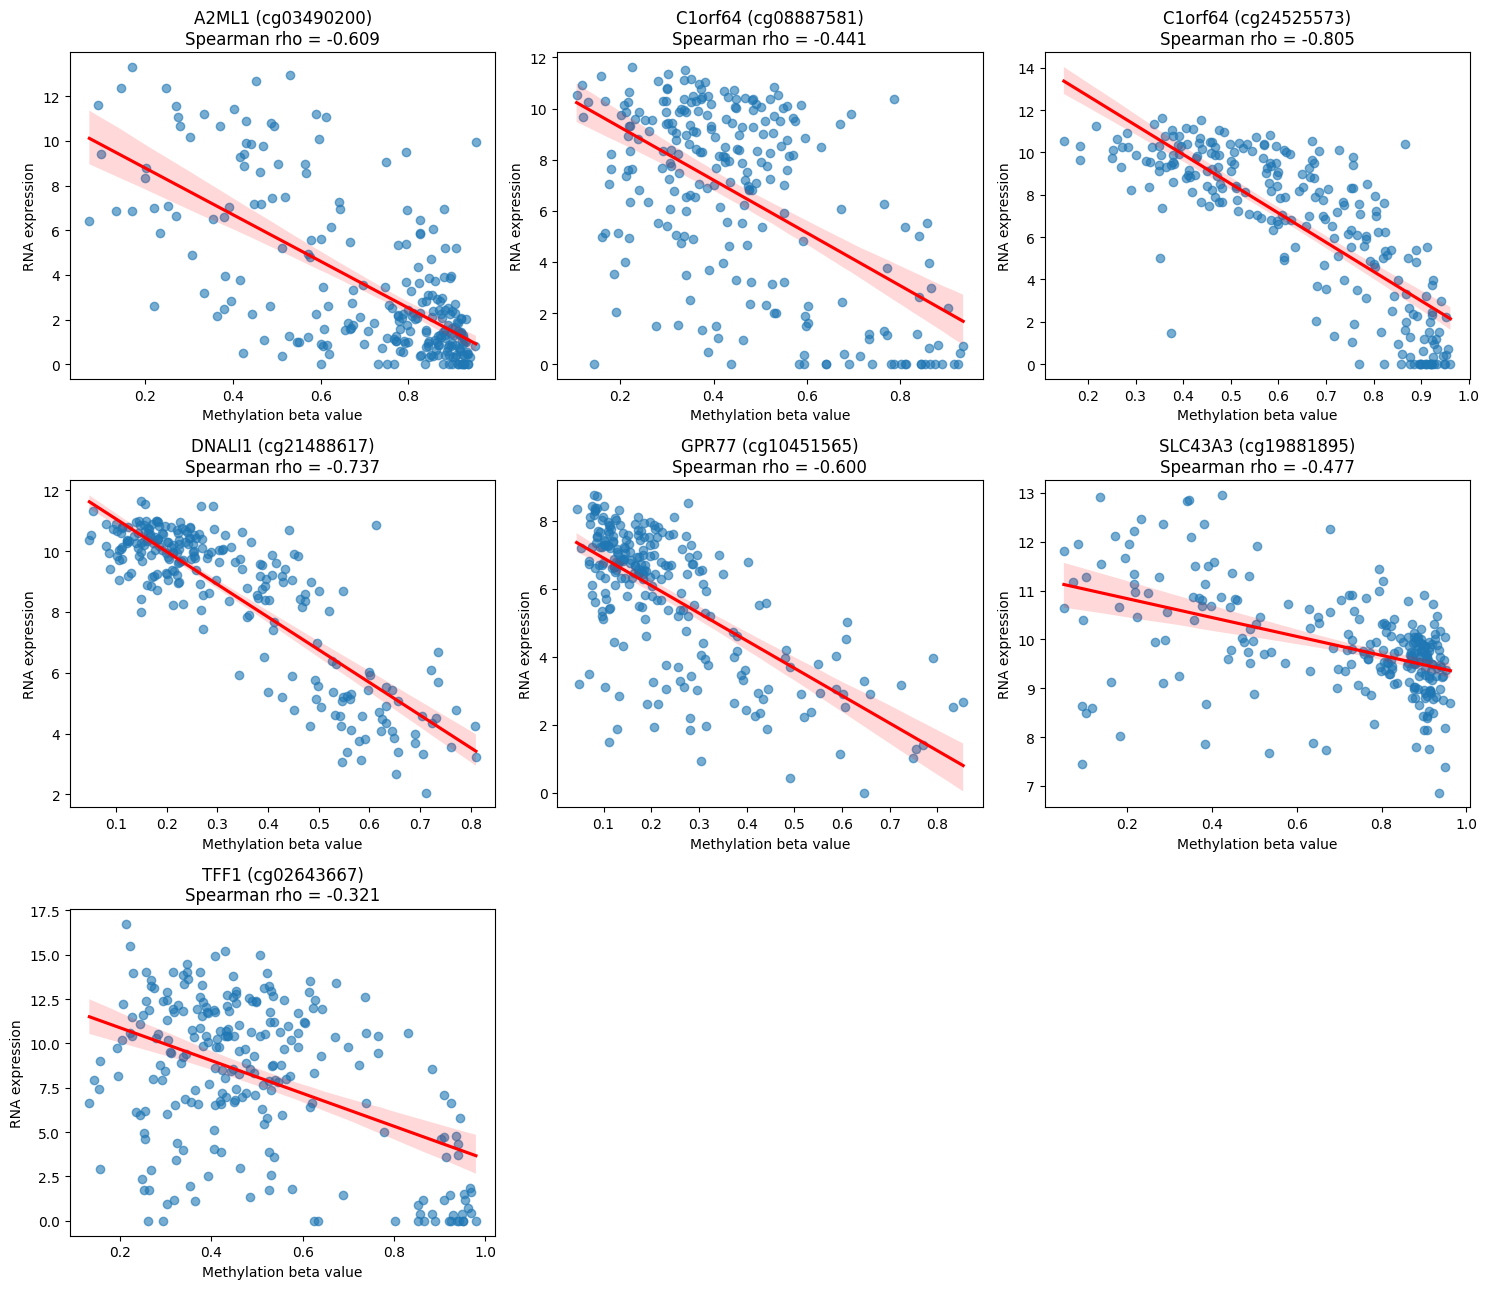

In [75]:
fig, axes = plt.subplots(3, 3, figsize=(15, 13))
axes = axes.flatten()

for i, (probe, gene) in enumerate(shared_probe_gene.items()):
    paired_data = pd.concat([x_meth_train[probe].rename("Methylation"),
                             x_rna_train[gene].rename("Expression")],axis=1).dropna()

    rho = correlation_df.loc[correlation_df["Probe"] == probe,"Spearman_rho"].iloc[0]

    sns.regplot(data=paired_data, x="Methylation", y="Expression",ax=axes[i],scatter_kws={"alpha": 0.6},line_kws={"color": "red"})

    axes[i].set_title(f"{gene} ({probe})\nSpearman rho = {rho:.3f}")
    axes[i].set_xlabel("Methylation beta value")
    axes[i].set_ylabel("RNA expression")

# Remove the two unused panels
for j in range(len(shared_probe_gene), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### Colour the plots by ER status

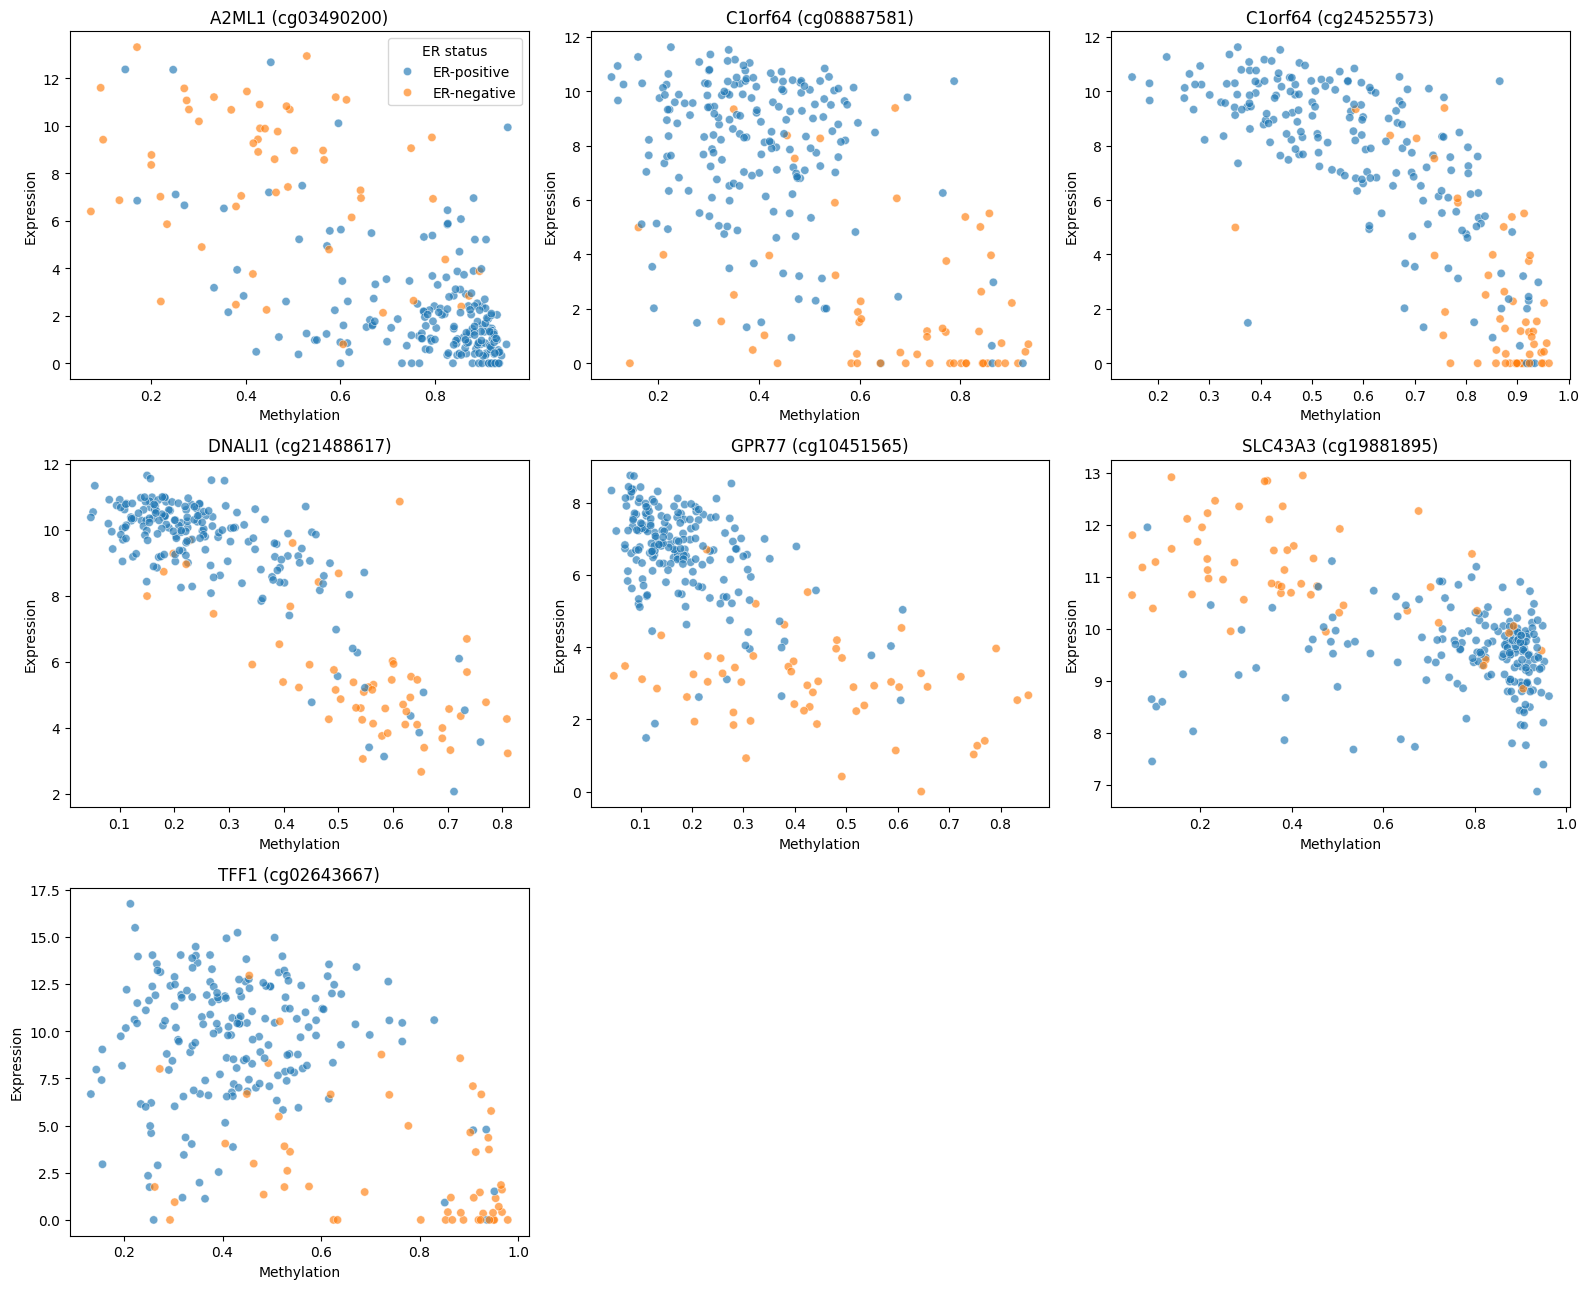

In [76]:
fig, axes = plt.subplots(3, 3, figsize=(16, 13))
axes = axes.flatten()

for i, (probe, gene) in enumerate(shared_probe_gene.items()):
    paired_data = pd.concat([x_meth_train[probe].rename("Methylation"),
                             x_rna_train[gene].rename("Expression"),
                             y_train.rename("ER_Status")],axis=1).dropna()

    paired_data["ER_Status"] = paired_data["ER_Status"].map({0: "ER-negative",1: "ER-positive"})

    sns.scatterplot(data=paired_data,x="Methylation",y="Expression",hue="ER_Status",alpha=0.65,ax=axes[i])

    axes[i].set_title(f"{gene} ({probe})")

    if i == 0:
        axes[i].legend(title="ER status")
    else:
        axes[i].get_legend().remove()

for j in range(len(shared_probe_gene), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [77]:
#spearmen correlation by ER status
group_correlation_results = []

for probe, gene in shared_probe_gene.items():
    paired_data = pd.concat([x_meth_train[probe].rename("Methylation"),
                             x_rna_train[gene].rename("Expression"),
                             y_train.rename("ER_Status")],axis=1).dropna()

    for status, label in [(1, "ER-positive"), (0, "ER-negative")]:
        group_data = paired_data[paired_data["ER_Status"] == status]
        rho, p_value = spearmanr(group_data["Methylation"],group_data["Expression"])

        group_correlation_results.append({
            "Gene": gene,
            "Probe": probe,
            "ER_group": label,
            "N": len(group_data),
            "Spearman_rho": rho,
            "p_value": p_value
        })

group_correlation_df = pd.DataFrame(group_correlation_results)

print(group_correlation_df.to_string(index=False))

   Gene      Probe    ER_group   N  Spearman_rho      p_value
  A2ML1 cg03490200 ER-positive 190     -0.399753 1.104263e-08
  A2ML1 cg03490200 ER-negative  55     -0.289177 3.224825e-02
C1orf64 cg08887581 ER-positive 190     -0.163523 2.417558e-02
C1orf64 cg08887581 ER-negative  55     -0.318207 1.790462e-02
C1orf64 cg24525573 ER-positive 190     -0.690643 2.902129e-28
C1orf64 cg24525573 ER-negative  55     -0.472877 2.666538e-04
 DNALI1 cg21488617 ER-positive 190     -0.575346 3.876970e-18
 DNALI1 cg21488617 ER-negative  55     -0.589610 2.174365e-06
  GPR77 cg10451565 ER-positive 190     -0.412802 3.246527e-09
  GPR77 cg10451565 ER-negative  55     -0.263853 5.159640e-02
SLC43A3 cg19881895 ER-positive 189     -0.175405 1.577094e-02
SLC43A3 cg19881895 ER-negative  55     -0.481746 1.961991e-04
   TFF1 cg02643667 ER-positive 190      0.018317 8.019377e-01
   TFF1 cg02643667 ER-negative  54     -0.358669 7.739053e-03
